# Reelmate · Phase 2 — *How many stars would I give it?*

**Goal.** Predict the rating (0.5–5 stars) that *one specific person* would give to a film they have not rated yet, explain the prediction, and rank their watchlist by how much they are likely to love each film.

**Data.** My own Letterboxd export (263 rated films) enriched with metadata from [TMDB](https://www.themoviedb.org).

**What this notebook does**

1. [Problem and data](#1.-Problem-and-data)
2. [Exploratory analysis](#2.-Exploratory-analysis)
3. [Feature engineering (and data leakage)](#3.-Feature-engineering)
4. [Baselines any model must beat](#4.-Baselines)
5. [Models and repeated cross-validation](#5.-Models)
6. [Metrics and comparison](#6.-Metrics)
7. [Interpretation: what drives my ratings, and where does the model fail?](#7.-Interpretation)
8. [Honest conclusions and the model that goes to the web](#8.-Conclusions)

> This is a *small-data* problem (a few hundred labels), so the emphasis is on honest validation rather than on fancy models.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # analysis/src
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from features import (FeatureBuilder, load_dataset, make_splits, cross_validate, metrics, clip,
                      MeanBaseline, TmdbDeviationBaseline, MIN_VOTES)
import models as Z

ACCENT, INK, GREY, RED = "#e0a021", "#1d1a25", "#8c8797", "#c8473d"
sns.set_theme(style="whitegrid", context="notebook", rc={"axes.edgecolor": "#cfcbd6", "grid.color": "#ebe8ef",
              "axes.titleweight": "bold", "axes.titlesize": 12, "figure.dpi": 110, "savefig.dpi": 110})
pd.set_option("display.max_columns", 30, "display.width", 140)

GENRES = {28: "Action", 12: "Adventure", 16: "Animation", 35: "Comedy", 80: "Crime", 99: "Documentary", 18: "Drama",
          10751: "Family", 14: "Fantasy", 36: "History", 27: "Horror", 10402: "Music", 9648: "Mystery",
          10749: "Romance", 878: "Sci-Fi", 10770: "TV Movie", 53: "Thriller", 10752: "War", 37: "Western"}

## 1. Problem and data

**Task.** Supervised *regression*: given the metadata of a film, predict the rating $y \in \{0.5, 1.0, \dots, 5.0\}$ this user would give it.

**Data.** `analysis/src/build_dataset.py` reads the Letterboxd export and looks every film up on TMDB (genres, director(s), top-5 cast, runtime, countries, original language, TMDB average vote, popularity). The dataset is rebuilt with that script and is **not** committed (it contains raw TMDB data).

**Constraint that shapes everything.** The final product trains the model *in the visitor's browser* from *their* ratings, so we need something that learns well from a few hundred labels, trains in milliseconds and can explain itself.

In [2]:
raw = pd.DataFrame(json.loads((Path.cwd().parent / "data" / "films.json").read_text(encoding="utf-8")))
print(raw.groupby(["split", "status"]).size().rename("films").to_frame())
df = load_dataset()                       # rated films that were found on TMDB
print(f"\nModelling dataset: {len(df)} rated films, {df.rating.nunique()} distinct rating values")
df.assign(year=df.year.astype(int))[["title", "year", "rating", "directors", "genres", "runtime", "vote", "votes"]].head(8)

                    films
split     status         
rated     doubtful      1
          ok          262
watchlist doubtful      1
          notfound      1
          ok          133

Modelling dataset: 263 rated films, 10 distinct rating values


,title,year,rating,directors,genres,runtime,vote,votes
0,Dune: Part Two,2024,5.0,[Denis Villeneuve],"[878, 12]",167.0,8.142,8986.0
1,La La Land,2016,4.0,[Damien Chazelle],"[35, 18, 10749]",129.0,7.900,18741.0
2,Oppenheimer,2023,5.0,[Christopher Nolan],"[18, 36, 10752]",181.0,8.023,12922.0
3,Dune,2021,4.5,[Denis Villeneuve],"[878, 12]",155.0,7.787,15974.0
4,Inception,2010,5.0,[Christopher Nolan],"[28, 878, 80]",148.0,8.373,40748.0
5,Spider-Man: Into the Spider-Verse,2018,3.5,"[Bob Persichetti, Peter Ramsey, Rodney Rothman]","[16, 28, 12, 878]",117.0,8.404,18258.0
6,Spider-Man: No Way Home,2021,4.0,[Jon Watts],"[28, 12, 878]",148.0,7.945,23578.0
7,Baby Driver,2017,3.5,[Edgar Wright],"[28, 80]",113.0,7.443,17433.0


## 2. Exploratory analysis

Before modelling: what does this person's rating behaviour look like?

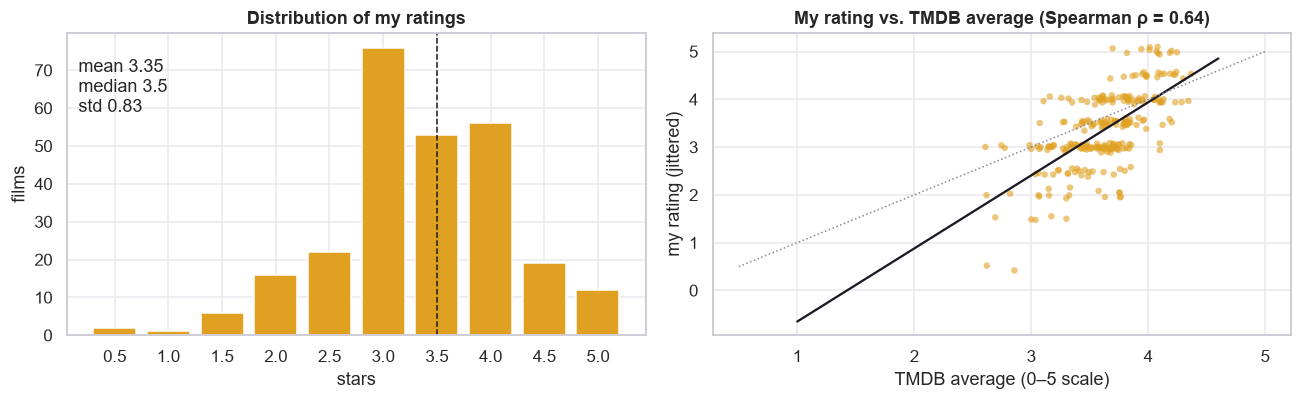

Slope of my rating on the TMDB score: 1.53  (1.0 would mean 'I follow the crowd exactly')


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
vc = df.rating.value_counts().reindex(np.arange(0.5, 5.01, 0.5), fill_value=0)
ax[0].bar(vc.index.astype(str), vc.values, color=ACCENT)
ax[0].axvline(x=list(vc.index).index(round(df.rating.mean() * 2) / 2), color=INK, ls="--", lw=1)
ax[0].set(title="Distribution of my ratings", xlabel="stars", ylabel="films")
ax[0].text(0.02, 0.92, f"mean {df.rating.mean():.2f}\nmedian {df.rating.median():.1f}\nstd {df.rating.std():.2f}", transform=ax[0].transAxes, va="top")

ok = df[(df.votes >= MIN_VOTES) & (df.vote > 0)]
rho, p = stats.spearmanr(ok.vote, ok.rating)
jit = np.random.default_rng(0).normal(0, 0.05, len(ok))
ax[1].scatter(ok.vote / 2, ok.rating + jit, s=18, alpha=.6, color=ACCENT, edgecolor="none")
b = np.polyfit(ok.vote / 2, ok.rating, 1)
xs = np.linspace(1, 4.6, 10)
ax[1].plot(xs, np.polyval(b, xs), color=INK)
ax[1].plot([0.5, 5], [0.5, 5], color=GREY, ls=":", lw=1)
ax[1].set(title=f"My rating vs. TMDB average (Spearman ρ = {rho:.2f})", xlabel="TMDB average (0–5 scale)", ylabel="my rating (jittered)")
plt.tight_layout(); plt.show()
print(f"Slope of my rating on the TMDB score: {b[0]:.2f}  (1.0 would mean 'I follow the crowd exactly')")

**Reading.** The distribution is skewed towards high ratings (people mostly watch films they expect to like) and the TMDB average is the single strongest signal, but with a lot of scatter: it explains a fraction of the variance, not all.

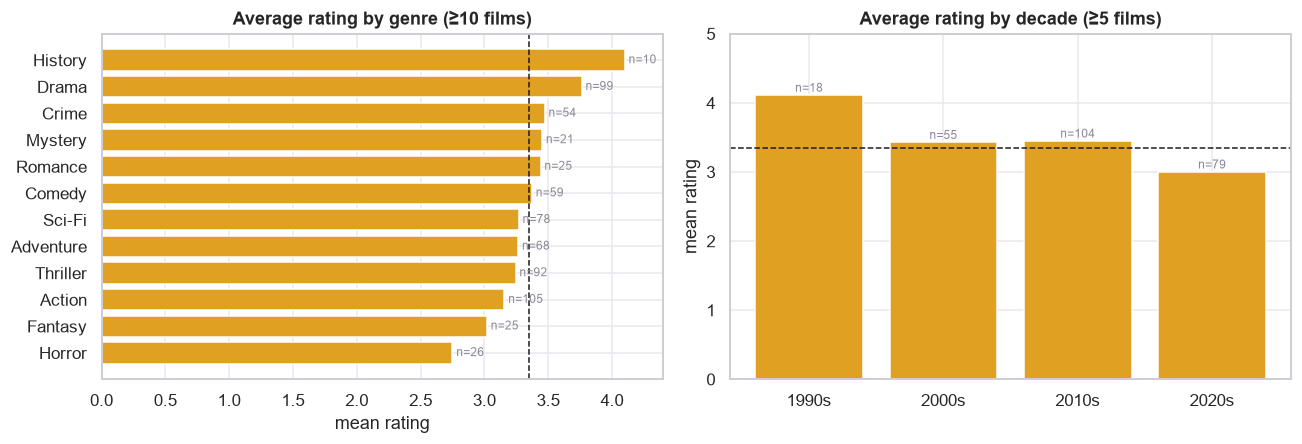

In [4]:
rows = []
for _, f in df.iterrows():
    for g in f.genres:
        rows.append({"genre": GENRES.get(g, g), "rating": f.rating})
gdf = pd.DataFrame(rows)
gs = gdf.groupby("genre").rating.agg(["mean", "count"])
gs = gs[gs["count"] >= 10].sort_values("mean")

d = df.assign(decade=(df.year // 10 * 10).astype(int))
ds = d.groupby("decade").rating.agg(["mean", "count"]); ds = ds[ds["count"] >= 5]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].barh(gs.index, gs["mean"], color=ACCENT)
for i, (m, n) in enumerate(zip(gs["mean"], gs["count"])): ax[0].text(m + .03, i, f"n={n}", va="center", fontsize=8, color=GREY)
ax[0].axvline(df.rating.mean(), color=INK, ls="--", lw=1)
ax[0].set(title="Average rating by genre (≥10 films)", xlim=(0, 4.4), xlabel="mean rating")
ax[1].bar(ds.index.astype(str) + "s", ds["mean"], color=ACCENT)
for i, n in enumerate(ds["count"]): ax[1].text(i, ds["mean"].iloc[i] + .05, f"n={n}", ha="center", fontsize=8, color=GREY)
ax[1].axhline(df.rating.mean(), color=INK, ls="--", lw=1)
ax[1].set(title="Average rating by decade (≥5 films)", ylim=(0, 5), ylabel="mean rating")
plt.tight_layout(); plt.show()

Spearman correlation with my rating:
runtime           0.32
log_popularity    0.34
year             -0.28
tmdb_vote         0.62


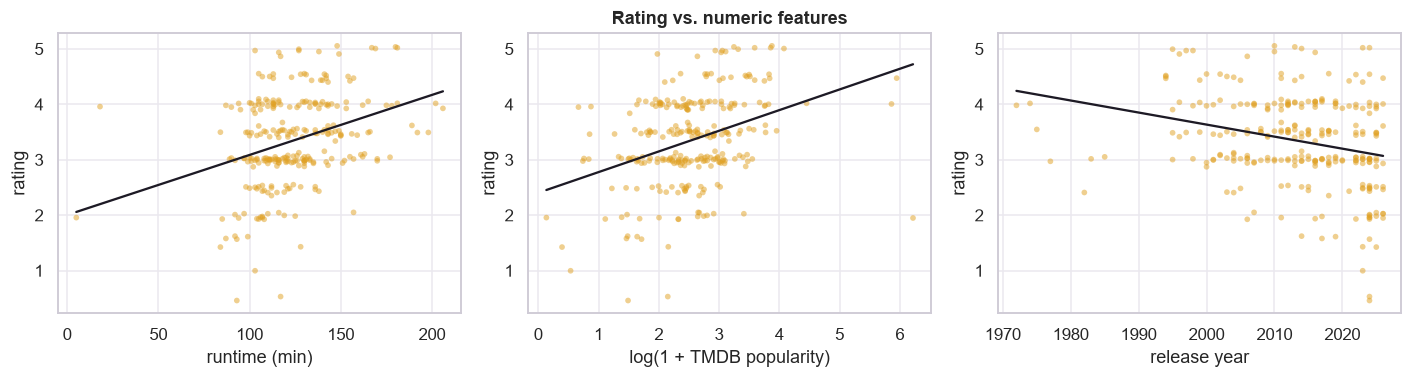

In [5]:
num = df.assign(log_popularity=np.log1p(df.popularity), year_=df.year)[["rating", "runtime", "log_popularity", "year_", "vote"]]
num = num.rename(columns={"year_": "year", "vote": "tmdb_vote"})
print("Spearman correlation with my rating:")
print(num.corr(method="spearman")["rating"].drop("rating").round(2).to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, col, lab in zip(ax, ["runtime", "log_popularity", "year"], ["runtime (min)", "log(1 + TMDB popularity)", "release year"]):
    a.scatter(num[col], num.rating + np.random.default_rng(1).normal(0, .06, len(num)), s=14, alpha=.5, color=ACCENT, edgecolor="none")
    m = num[[col, "rating"]].dropna(); a.plot(*zip(*sorted(zip(m[col], np.polyval(np.polyfit(m[col], m.rating, 1), m[col])))), color=INK)
    a.set(xlabel=lab, ylabel="rating")
ax[1].set_title("Rating vs. numeric features")
plt.tight_layout(); plt.show()

In [6]:
dr = df.explode("directors").dropna(subset=["directors"]).groupby("directors").rating.agg(["mean", "count"])
C0, m = df.rating.mean(), 3
dr["bayesian"] = (dr["count"] * dr["mean"] + m * C0) / (dr["count"] + m)
print("Directors with ≥3 rated films, ordered by Bayesian average (m=3):")
print(dr[dr["count"] >= 3].sort_values("bayesian", ascending=False).round(2).head(10).to_string())
print(f"\nDirectors with exactly 1 film in my data: {(dr['count'] == 1).sum()} of {len(dr)}  ->  most directors are 'unseen' for the model")

Directors with ≥3 rated films, ordered by Bayesian average (m=3):
                   mean  count  bayesian
directors                               
Christopher Nolan  4.58      6      4.17
Denis Villeneuve   4.62      4      4.08
Martin Scorsese    4.67      3      4.01
Quentin Tarantino  4.00      5      3.76
Damien Chazelle    4.00      3      3.67
Nick Cassavetes    3.83      3      3.59
David Fincher      3.75      4      3.58
Todd Phillips      3.70      5      3.57
James Cameron      3.67      3      3.51
Rian Johnson       3.67      3      3.51

Directors with exactly 1 film in my data: 141 of 191  ->  most directors are 'unseen' for the model


**Take-aways from the EDA**

* Ratings are concentrated at the high end, so a model that always predicts the mean is already not terrible — the bar to beat is not zero.
* The TMDB average carries real signal (ρ above), which makes "my mean + the film's deviation from TMDB" a **strong** baseline.
* Genre and decade effects exist but are modest and rest on few films per group.
* Director/actor effects are potentially large but **extremely sparse**: most directors appear once. Estimating them naively from a handful of films would be noisy → we need *smoothing* (see next section).

## 3. Feature engineering

| Feature | Description |
|---|---|
| `genre_*` | one-hot for each TMDB genre that has ≥ 5 films in the training fold |
| `decade` | release decade, numeric (`(floor(year/10)·10 − 1900)/10`) |
| `runtime` | minutes (missing → training median) |
| `log_popularity` | `log(1 + TMDB popularity)` — popularity is extremely right-skewed |
| `tmdb_vote` | TMDB average on a 0–5 scale, **Bayesian-adjusted for the number of votes** (section 3.3) |
| `english` | 1 if the original language is English |
| `country_*` | one-hot for countries with ≥ 8 films in the training fold |
| `director_te`, `cast_te` | **smoothed target encoding** of the director(s) and the top-5 cast (see below) |

### 3.1 Smoothed (Bayesian) target encoding
For a director (or actor) with $n$ rated films and mean rating $\bar r$, and global mean $C$, the encoded value is the Bayesian average **minus** the global mean:

$$\text{dev} = \frac{n\,\bar r + m\,C}{n + m} - C = \frac{\sum r - nC}{n + m}, \qquad m = 3$$

It is exactly the average the web dashboard uses to rank directors. A director with a single 5★ film gets only a *small* positive value, not "5". For films with several directors / actors we average the values. Unknown people get 0 ("no information").

### 3.2 Data leakage, and how we avoid it
**Data leakage** is when information from outside the training data — typically the label of the very rows you evaluate on — sneaks into the features, so the validation score is better than what you would get on genuinely new data.

Target encoding is a classic leak: if the director's mean is computed on *all* 263 films and then we cross-validate, the encoding of every test film already contains **its own rating**. For a director with a single film, the feature *is* the label.

We avoid it in two places:

1. **Per fold.** The encoding statistics (and global mean $C$, imputation values, the list of genre/country columns) are fitted **only on the training fold**; test films are encoded with those statistics.
2. **Leave-one-out inside the training fold.** When encoding a *training* film we remove its own rating from its director's statistics; otherwise the model would learn to over-trust an encoding that, in training, secretly contains the answer.

The cell below makes the damage visible by comparing the correct pipeline with a deliberately leaky one.

In [7]:
fb = FeatureBuilder(); X_all = fb.fit_transform(df)
print(f"{X_all.shape[1]} features on the full data. Columns:", ", ".join(X_all.columns))
X_all.assign(title=df.title, rating=df.rating).set_index("title").iloc[:6, [0, 1, 2, 3, 4, 5, 6, -1]].round(2)

25 features on the full data. Columns: decade, runtime, log_popularity, tmdb_vote, english, director_te, cast_te, genre_12, genre_14, genre_18, genre_27, genre_28, genre_35, genre_36, genre_53, genre_80, genre_878, genre_9648, genre_10749, genre_10751, genre_10752, country_AU, country_DE, country_GB, country_US


,decade,runtime,log_popularity,tmdb_vote,english,director_te,cast_te,rating
title,,,,,,,,
Dune: Part Two,12.0,167.0,3.86,4.03,1.0,0.58,0.16,5.0
La La Land,11.0,129.0,2.93,3.93,1.0,0.26,-0.03,4.0
Oppenheimer,12.0,181.0,3.59,3.98,1.0,0.72,0.05,5.0
Dune,12.0,155.0,3.75,3.87,1.0,0.66,0.14,4.5
Inception,11.0,148.0,3.88,4.18,1.0,0.72,0.09,5.0
Spider-Man: Into the Spider-Verse,11.0,117.0,3.35,4.18,1.0,0.00,0.07,3.5


In [8]:
splits = make_splits(len(df), n_splits=5, n_repeats=10, seed=42)        # 50 folds, shared by EVERY model below
y = df.rating.to_numpy(float)

def cv_leaky(model_factory):
    # WRONG on purpose: target encoding fitted on ALL films (no per-fold fit, no leave-one-out)
    leaky = FeatureBuilder().fit(df)
    X = leaky.transform(df.assign(rating=np.nan))     # 'rating' is not used when loo=False
    maes = []
    for tr, te, _ in splits:
        m = model_factory().fit(X.iloc[tr], y[tr])
        maes.append(metrics(y[te], m.predict(X.iloc[te]))["MAE"])
    return np.mean(maes)

correct, _ = cross_validate(df, {"Random Forest": Z.random_forest, "Ridge": Z.ridge}, splits[:20])
correct = correct.groupby("model").MAE.mean()
leak = {k: cv_leaky(f) for k, f in {"Random Forest": Z.random_forest, "Ridge": Z.ridge}.items()}
pd.DataFrame({"MAE — correct (per fold + LOO)": correct, "MAE — leaky (encoding on all data)": pd.Series(leak)}).assign(
    **{"fake improvement": lambda t: t.iloc[:, 0] - t.iloc[:, 1]}).round(3)

,MAE — correct (per fold + LOO),MAE — leaky (encoding on all data),fake improvement
Random Forest,0.474,0.180,0.294
Ridge,0.477,0.194,0.283


The leaky pipeline reports a visibly **lower (better) error**, especially for the flexible Random Forest — an improvement that would vanish in production, because a new film's director is encoded without knowing its rating. From here on, every number uses the correct pipeline.

### 3.3 Unreliable TMDB scores: a Bayesian adjustment
The TMDB average is the strongest feature, but it is only as good as the number of votes behind it: *Whistle* has a perfect 5.0 from **one** vote. Instead of trusting or discarding such scores with a hard threshold, we shrink them towards the global TMDB mean with the same Bayesian idea used for directors:

1809R_{adj} = \frac{v\,R + m\,C}{v + m}, \qquad v=\text{vote count},\; R=\text{TMDB average},\; C = 6.5\;(\text{global TMDB mean}),\; m=\text{prior weight in votes}1809

A film with thousands of votes keeps its score; one with 1 vote becomes ≈ C ("no information"). How large should $ be? Below: error vs. $ (same 20 folds for every point). =0$ is the raw score.

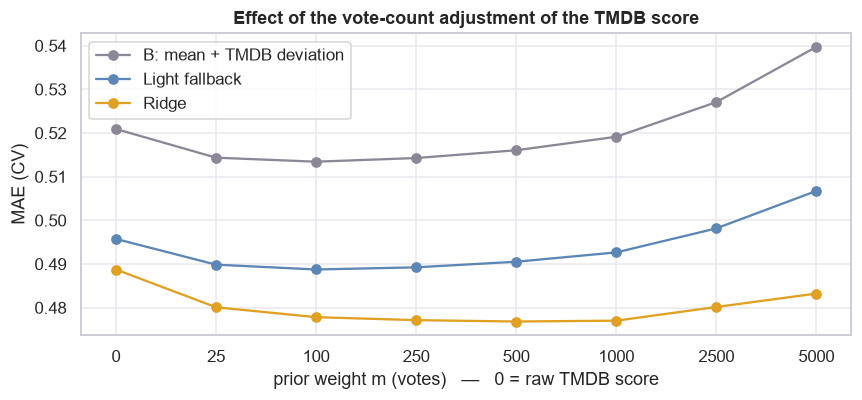

                            0       25      100     250     500     1000    2500    5000
model                                                                                   
B: mean + TMDB deviation  0.5209  0.5143  0.5134  0.5143  0.5160  0.5191  0.5271  0.5397
Light fallback            0.4957  0.4898  0.4887  0.4892  0.4905  0.4926  0.4982  0.5067
Ridge                     0.4887  0.4801  0.4778  0.4771  0.4768  0.4770  0.4801  0.4832


In [9]:
sweep = []
sp20 = splits[:20]
for m_ in [0, 25, 100, 250, 500, 1000, 2500, 5000]:
    r_, _ = cross_validate(df, {"B: mean + TMDB deviation": TmdbDeviationBaseline, "Light fallback": Z.TmdbGenreFallback, "Ridge": Z.ridge}, sp20, vote_m=m_)
    sweep.append(r_.groupby("model").MAE.mean().rename(m_))
sweep = pd.DataFrame(sweep)
fig, ax = plt.subplots(figsize=(8, 3.8))
for col, c in zip(sweep.columns, [GREY, "#5b86b5", ACCENT]):
    ax.plot(range(len(sweep)), sweep[col], marker="o", label=col, color=c)
ax.set_xticks(range(len(sweep))); ax.set_xticklabels(sweep.index)
ax.set(xlabel="prior weight m (votes)   —   0 = raw TMDB score", ylabel="MAE (CV)", title="Effect of the vote-count adjustment of the TMDB score"); ax.legend()
plt.tight_layout(); plt.show()
print(sweep.round(4).T.to_string())

**Reading.** Any shrinkage beats the raw score, and the curve is **flat between m ≈ 100 and 1000** (Ridge: best around 500). We do not hand-pick $ on this curve: the nested CV in section 6.1 chooses it inside every training fold. For the web app (which cannot tune per user) we fix **m = 500**, in the middle of that plateau.

## 4. Baselines

Any model has to beat simple rules, otherwise it adds complexity for nothing.

* **Baseline A — always my mean.** $\hat y = \bar y_{\text{train}}$.
* **Baseline B — my mean + the film's deviation from TMDB.** $\hat y = \bar y_{\text{train}} + (\text{TMDB}_{0\text{–}5} - \overline{\text{TMDB}}_{\text{train}})$. It says "I rate like the crowd, only shifted by how generous I am". It has **no fitted parameter other than the mean**.

In [10]:
res_base, _ = cross_validate(df, Z.BASELINES, splits)
res_base.groupby("model")[["MAE", "RMSE", "within_0.5"]].mean().round(3)

,MAE,RMSE,within_0.5
model,,,
Baseline A: my mean,0.658,0.827,49.046
Baseline B: mean + TMDB deviation,0.517,0.662,58.057


## 5. Models

Four model families (plus the light fallback used by the web for small profiles), **all evaluated on the very same 50 folds** (5-fold CV repeated 10 times with different shuffles; `random_state=42`):

| Model | Why it is here | Hyper-parameters |
|---|---|---|
| **Light fallback** | TMDB score shifted to my mean + shrunk genre effects; no director/actor info. The model the web uses with < 30 ratings | none (closed form) |
| **Ridge** | linear, interpretable, trains instantly | α picked by efficient leave-one-out *inside each training fold* (grid 0.1–1000). The TMDB-score slope is left (almost) unpenalised, see below |
| **k-NN** | "films similar to the ones I liked" | k ∈ {5,…,40}, picked by inner 5-fold CV |
| **Random Forest** | non-linear interactions | 300 trees, `min_samples_leaf=3`, `max_features=0.4` |
| **Gradient Boosting** | usual state of the art on tabular data | `HistGradientBoostingRegressor`, depth 3, lr 0.04, 150 iterations, L2 = 1 |

Features are rebuilt in every fold (section 3). Predictions are clipped to [0.5, 5].

In [11]:
import time
t0 = time.time()
ALL = {**Z.BASELINES, **Z.MODELS}
res, oof = cross_validate(df, ALL, splits)
print(f"{len(splits)} folds x {len(ALL)} models in {time.time() - t0:.0f}s")

50 folds x 7 models in 35s


## 6. Metrics

* **MAE** — mean absolute error in stars (the most intuitive).
* **RMSE** — penalises big misses more.
* **Within 0.5★** — share of predictions at most half a star from the true rating (the granularity of the rating scale itself).

Mean ± standard deviation across the 50 folds (the folds of one repetition share no test film, but different repetitions reuse films, so the ± describes *variability between folds*, not a formal confidence interval).

In [12]:
order = ["Baseline A: my mean", "Baseline B: mean + TMDB deviation", "Light fallback (TMDB + genres)", "Ridge", "k-NN", "Random Forest", "Gradient Boosting"]
g = res.groupby("model")
table = pd.DataFrame({
    "MAE": g.MAE.mean().round(3), "MAE ±": g.MAE.std().round(3),
    "RMSE": g.RMSE.mean().round(3), "RMSE ±": g.RMSE.std().round(3),
    "within 0.5★ (%)": g["within_0.5"].mean().round(1), "within ±": g["within_0.5"].std().round(1),
}).loc[order]
table["MAE gain vs A"] = ((1 - table.MAE / table.loc[order[0], "MAE"]) * 100).round(1).astype(str) + " %"
table["MAE gain vs B"] = ((1 - table.MAE / table.loc[order[1], "MAE"]) * 100).round(1).astype(str) + " %"
table

,MAE,MAE ±,RMSE,RMSE ±,within 0.5★ (%),within ±,MAE gain vs A,MAE gain vs B
model,,,,,,,,
Baseline A: my mean,0.658,0.057,0.827,0.071,49.0,6.1,0.0 %,-27.3 %
Baseline B: mean + TMDB deviation,0.517,0.054,0.662,0.062,58.1,6.2,21.4 %,0.0 %
Light fallback (TMDB + genres),0.491,0.053,0.635,0.062,61.1,6.6,25.4 %,5.0 %
Ridge,0.479,0.050,0.609,0.055,59.6,6.7,27.2 %,7.4 %
k-NN,0.534,0.047,0.689,0.059,56.5,5.3,18.8 %,-3.3 %
Random Forest,0.473,0.052,0.609,0.063,61.6,6.8,28.1 %,8.5 %
Gradient Boosting,0.493,0.048,0.627,0.056,60.0,6.5,25.1 %,4.6 %


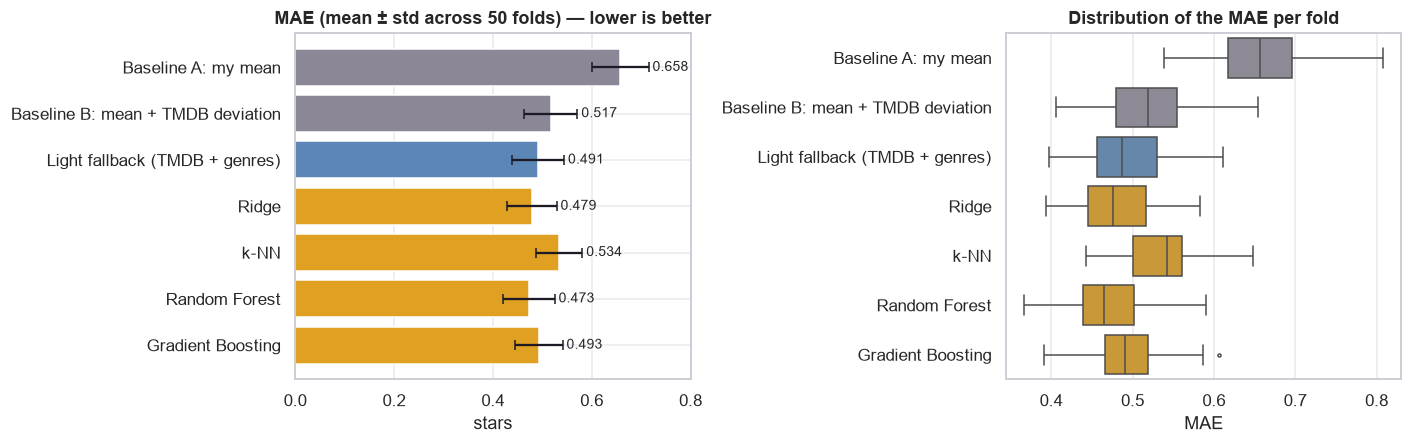

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
cols = [GREY, GREY, "#5b86b5", ACCENT, ACCENT, ACCENT, ACCENT]
mm = table["MAE"]; ss = table["MAE ±"]
ax[0].barh(order[::-1], mm[::-1], xerr=ss[::-1], color=cols[::-1], capsize=3, ecolor=INK)
for i, (m, s) in enumerate(zip(mm[::-1], ss[::-1])): ax[0].text(m + s + .008, i, f"{m:.3f}", va="center", fontsize=9)
ax[0].set(title="MAE (mean ± std across 50 folds) — lower is better", xlim=(0, .8), xlabel="stars")
sns.boxplot(data=res.assign(model=pd.Categorical(res.model, order)), y="model", x="MAE", ax=ax[1], palette=cols, orient="h", fliersize=2, linewidth=1)
ax[1].set(title="Distribution of the MAE per fold", ylabel="")
plt.tight_layout(); plt.show()

**Is the gap between models real?** Folds are paired (same test films for every model), so we can look at the *per-fold difference* in MAE against Ridge, which removes most of the "easy fold / hard fold" noise.

In [14]:
piv = res.pivot_table(index="fold", columns="model", values="MAE")
rows = []
for name in order:
    if name == "Ridge": continue
    d_ = piv[name] - piv["Ridge"]
    rows.append({"model vs Ridge": name, "mean MAE diff": d_.mean(), "folds where it beats Ridge": f"{(d_ < 0).mean() * 100:.0f} %",
                 "Wilcoxon p": stats.wilcoxon(d_).pvalue})
pd.DataFrame(rows).set_index("model vs Ridge").round(4)

,mean MAE diff,folds where it beats Ridge,Wilcoxon p
model vs Ridge,,,
Baseline A: my mean,0.1790,0 %,0.0000
Baseline B: mean + TMDB deviation,0.0379,2 %,0.0000
Light fallback (TMDB + genres),0.0127,22 %,0.0000
k-NN,0.0558,2 %,0.0000
Random Forest,-0.0052,54 %,0.1571
Gradient Boosting,0.0148,30 %,0.0024


### 6.1 Official numbers: nested cross-validation
In the table above Ridge's setup (vote prior =500$, how much the TMDB slope is shrunk) was *chosen after looking at this same cross-validation*, so those scores are slightly optimistic: the test folds helped to pick the configuration. **Nested CV** removes that: in every outer training set an *inner* 5-fold CV picks the hyper-parameters (Ridge:  \in \{0,100,250,500,1000,2500\}$ × TMDB-slope scale $\in \{1,3,10,30,100\}$; fallback: $ only; α by leave-one-out in every fit) and the outer test fold is only used once to score it. **The nested numbers are the official results for the two models that go to the web**; the plain rows are kept for comparison.

In [15]:
nres, noof, chosen = Z.nested_cv(df, splits, "ridge")
fres, foof, fchosen = Z.nested_cv(df, splits, "fallback")
cmp_ = pd.DataFrame({
    "Light fallback (m=500 fixed, table above)": res[res.model == "Light fallback (TMDB + genres)"][["MAE", "RMSE", "within_0.5"]].mean(),
    "Light fallback (nested CV) - OFFICIAL": fres[["MAE", "RMSE", "within_0.5"]].mean(),
    "Ridge (m=500, scale=10 fixed, table above)": res[res.model == "Ridge"][["MAE", "RMSE", "within_0.5"]].mean(),
    "Ridge (nested CV) - OFFICIAL": nres[["MAE", "RMSE", "within_0.5"]].mean()}).T.round(3)
cmp_["MAE ±"] = [res[res.model == "Light fallback (TMDB + genres)"].MAE.std().round(3), fres.MAE.std().round(3), res[res.model == "Ridge"].MAE.std().round(3), nres.MAE.std().round(3)]
display(cmp_)
print("Ridge, (m, slope-scale) chosen by the inner CV in the 50 outer folds:", {k: int(v) for k, v in pd.Series(chosen).value_counts().items()})
print("Fallback, m chosen by the inner CV:", {k[0]: int(v) for k, v in pd.Series(fchosen).value_counts().items()})
print(f"Optimism of the non-nested numbers: Ridge {nres.MAE.mean() - res[res.model == 'Ridge'].MAE.mean():+.4f}★, fallback {fres.MAE.mean() - res[res.model == 'Light fallback (TMDB + genres)'].MAE.mean():+.4f}★")

,MAE,RMSE,within_0.5,MAE ±
"Light fallback (m=500 fixed, table above)",0.491,0.635,61.138,0.053
Light fallback (nested CV) - OFFICIAL,0.491,0.637,61.632,0.053
"Ridge (m=500, scale=10 fixed, table above)",0.479,0.609,59.578,0.050
Ridge (nested CV) - OFFICIAL,0.483,0.619,59.848,0.048


Ridge, (m, slope-scale) chosen by the inner CV in the 50 outer folds: {(2500.0, 3.0): 10, (1000.0, 3.0): 10, (250.0, 3.0): 5, (500.0, 3.0): 5, (1000.0, 10.0): 4, (250.0, 10.0): 4, (500.0, 10.0): 3, (100.0, 10.0): 3, (250.0, 100.0): 2, (100.0, 3.0): 1, (0.0, 3.0): 1, (2500.0, 10.0): 1, (250.0, 30.0): 1}
Fallback, m chosen by the inner CV: {100.0: 43, 250.0: 5, 0.0: 2}
Optimism of the non-nested numbers: Ridge +0.0043★, fallback +0.0002★


In [16]:
# Which alpha does Ridge choose inside each fold?
from sklearn.preprocessing import StandardScaler
alphas = []
for tr, te, _ in splits:
    f = FeatureBuilder(); Xtr = f.fit_transform(df.iloc[tr])
    alphas.append(Z.PartialRidge().fit(Xtr, y[tr]).alpha_)
print(f"alpha chosen inside the folds: median {np.median(alphas):.1f}, IQR {np.percentile(alphas, 25):.1f}–{np.percentile(alphas, 75):.1f}")

alpha chosen inside the folds: median 379.3, IQR 233.6–379.3


## 7. Interpretation
### 7.1 What weighs most?
Left: the Ridge coefficients (on standardised features, fitted on all 263 films), i.e. stars gained per standard deviation of the feature. Right: **permutation importance** on held-out folds — how much the MAE grows when one feature is shuffled; it is model-agnostic, so we show it for Ridge and for the Random Forest.

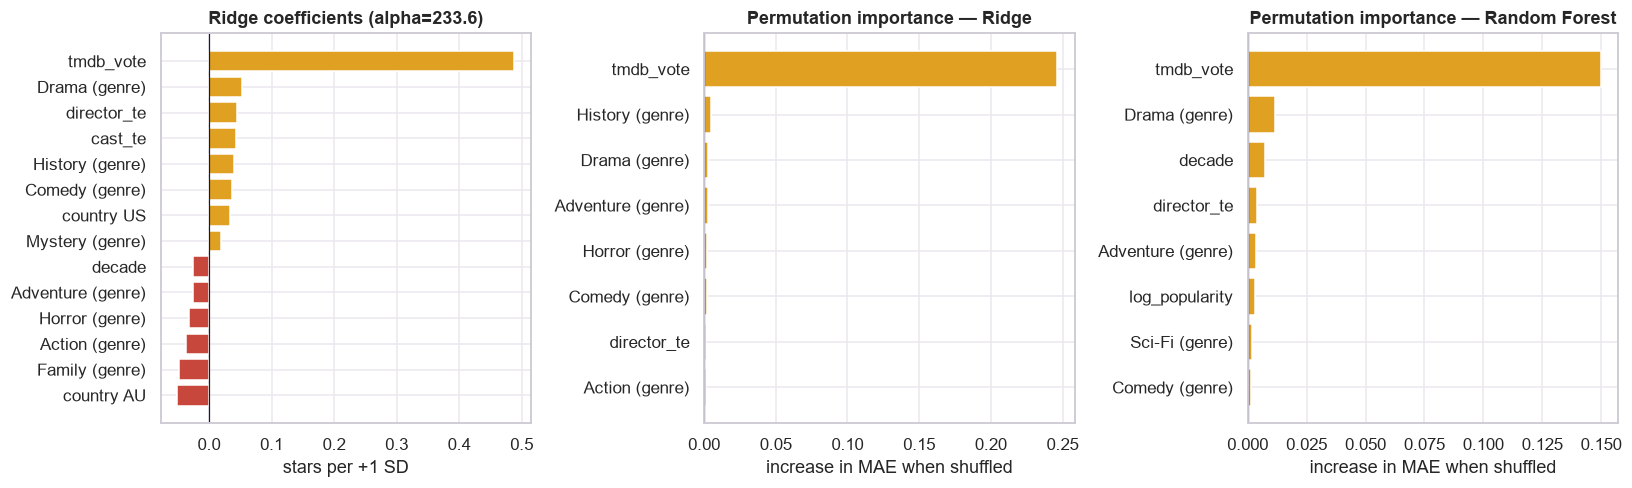

In [17]:
from sklearn.inspection import permutation_importance
fbk = FeatureBuilder(); Xf = fbk.fit_transform(df)
rr = Z.PartialRidge().fit(Xf, y); sc = rr.scaler_
name = lambda c: (GENRES.get(int(c.split("_")[1]), c) + " (genre)") if c.startswith("genre_") else (f"country {c.split('_')[1]}" if c.startswith("country_") else c)
coef = pd.Series(rr.coef_std_, index=[name(c) for c in Xf.columns]).sort_values()
top = pd.concat([coef.head(6), coef.tail(8)])

# permutation importance on held-out folds (first repetition = 5 disjoint test sets)
imp = {k: [] for k in ["Ridge", "Random Forest"]}
for tr, te, rep in splits[:5]:
    f = FeatureBuilder(); Xtr = f.fit_transform(df.iloc[tr]); Xte = f.transform(df.iloc[te])
    for k, mk in {"Ridge": Z.ridge, "Random Forest": Z.random_forest}.items():
        m = mk().fit(Xtr, y[tr])
        pi = permutation_importance(m, Xte, y[te], scoring="neg_mean_absolute_error", n_repeats=20, random_state=0)
        imp[k].append(pd.Series(pi.importances_mean, index=Xte.columns))
imp = {k: pd.concat(v, axis=1).mean(axis=1).rename(index=name) for k, v in imp.items()}

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].barh(top.index, top.values, color=[ACCENT if v > 0 else RED for v in top.values]); ax[0].axvline(0, color=INK, lw=.8)
ax[0].set(title=f"Ridge coefficients (alpha={rr.alpha_:.1f})", xlabel="stars per +1 SD")
for a, (k, s) in zip(ax[1:], imp.items()):
    s = s.sort_values().tail(8); a.barh(s.index, s.values, color=ACCENT); a.axvline(0, color=INK, lw=.8)
    a.set(title=f"Permutation importance — {k}", xlabel="increase in MAE when shuffled")
plt.tight_layout(); plt.show()

In [18]:
sd = pd.Series(sc.scale_, index=Xf.columns)
print("Ridge coefficients converted to natural units:")
print(f"  +1 TMDB star (=2 TMDB points):   {rr.coef_std_[list(Xf.columns).index('tmdb_vote')] / sd['tmdb_vote']:+.2f} stars")
print(f"  director_te (+1 = +1 star):      {rr.coef_std_[list(Xf.columns).index('director_te')] / sd['director_te']:+.2f}")
print(f"  cast_te     (+1 = +1 star):      {rr.coef_std_[list(Xf.columns).index('cast_te')] / sd['cast_te']:+.2f}")

Ridge coefficients converted to natural units:
  +1 TMDB star (=2 TMDB points):   +1.52 stars
  director_te (+1 = +1 star):      +0.22
  cast_te     (+1 = +1 star):      +0.59


### 7.2 Predicted vs. actual
Out-of-fold predictions (each film is predicted by models that never saw it; averaged over the 10 repetitions). Points are jittered because actual ratings are discrete.

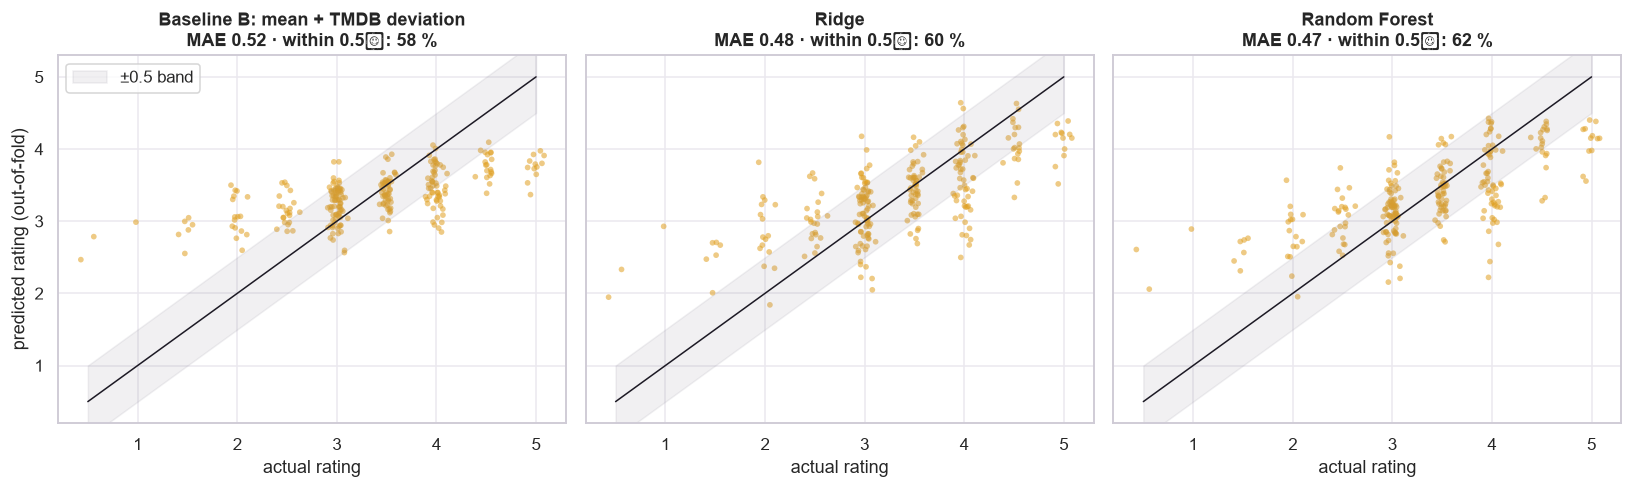

Mean prediction for each true rating (Ridge) — the model 'shrinks' to the middle:
actual   0.5   1.0   1.5    2.0    2.5    3.0    3.5   4.0    4.5    5.0
mean    2.14  2.93  2.51   2.86   3.03   3.11   3.44   3.6   4.07   4.09
count   2.00  1.00  6.00  16.00  22.00  76.00  53.00  56.0  19.00  12.00


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for a, k in zip(ax, ["Baseline B: mean + TMDB deviation", "Ridge", "Random Forest"]):
    p = oof[k]; j = np.random.default_rng(2).normal(0, .045, len(y))
    a.scatter(y + j, p, s=14, alpha=.55, color=ACCENT, edgecolor="none"); a.plot([.5, 5], [.5, 5], color=INK, lw=1)
    a.fill_between([.5, 5], [0, 4.5], [1, 5.5], color=GREY, alpha=.12, label="±0.5 band")
    mt = metrics(y, p); a.set(title=f"{k}\nMAE {mt['MAE']:.2f} · within 0.5★: {mt['within_0.5']:.0f} %", xlabel="actual rating", xlim=(.2, 5.3), ylim=(.2, 5.3))
ax[0].set_ylabel("predicted rating (out-of-fold)"); ax[0].legend(loc="upper left")
plt.tight_layout(); plt.show()
print("Mean prediction for each true rating (Ridge) — the model 'shrinks' to the middle:")
print(pd.DataFrame({"actual": y, "pred": oof["Ridge"]}).groupby("actual").pred.agg(["mean", "count"]).round(2).T.to_string())

### 7.3 Biggest mistakes
The ten largest out-of-fold errors of Ridge.

In [20]:
err = df[["title", "year", "rating", "vote", "votes", "directors", "genres"]].copy()
err["pred"] = oof["Ridge"]; err["error"] = err.pred - err.rating
err["tmdb (0-5)"] = (err.vote / 2).round(1)
err["directors"] = err.directors.str.join(", ").str.slice(0, 26)
err["genres"] = err.genres.map(lambda gs: ", ".join(GENRES.get(g, "?") for g in gs[:2]))
worst = err.reindex(err.error.abs().sort_values(ascending=False).index).head(10)
worst.assign(year=worst.year.astype(int))[["title", "year", "rating", "pred", "error", "tmdb (0-5)", "votes", "directors", "genres"]].round(2).reset_index(drop=True)

,title,year,rating,pred,error,tmdb (0-5),votes,directors,genres
0,Crypto Boy,2023,1.0,2.93,1.93,3.1,45.0,Shady El-Hamus,Drama
1,Werewolves,2024,0.5,2.33,1.83,2.9,546.0,Steven C. Miller,"Action, Horror"
2,Zodiac,2007,2.0,3.82,1.82,3.8,12138.0,David Fincher,"Crime, Mystery"
3,Obsession,2025,4.0,2.50,-1.50,4.5,1.0,Audrey Collins,Thriller
4,A Time to Kill,1996,5.0,3.52,-1.48,3.7,3174.0,Joel Schumacher,"Crime, Drama"
5,Madame Web,2024,0.5,1.95,1.45,2.6,2772.0,SJ Clarkson,"Action, Fantasy"
6,War Machine,2026,2.0,3.34,1.34,3.8,2734.0,Patrick Hughes,"Action, Sci-Fi"
7,The Hangover Part III,2013,4.0,2.67,-1.33,3.1,9555.0,Todd Phillips,Comedy
8,Resident Evil,2026,2.0,3.29,1.29,3.8,2257.0,Zach Cregger,"Horror, Sci-Fi"
9,Nosferatu,2024,4.0,2.74,-1.26,3.4,4166.0,Robert Eggers,"Horror, Fantasy"


In [21]:
print(f"Share of films with |error| > 1 star: {(err.error.abs() > 1).mean() * 100:.0f} %")
print(f"Mean error when I gave 0.5–1.5★: {err[err.rating <= 1.5].error.mean():+.2f}  |  when I gave 5★: {err[err.rating == 5].error.mean():+.2f}")

Share of films with |error| > 1 star: 11 %
Mean error when I gave 0.5–1.5★: +1.26  |  when I gave 5★: -0.91


**Why does it fail on those films?** Almost every large error falls into one of three patterns:

1. **Opinions that go against the crowd, in a way no metadata can capture.** *Zodiac* (TMDB 3.8/5, I gave 2★), *Madame Web* and *Werewolves* (0.5★), *A Time to Kill* (5★ vs TMDB 3.7), *The Hangover Part III* (4★ vs TMDB 3.1) or *Nosferatu*. The model only knows "what films like this usually get", so a strong personal reaction to *this particular* film is invisible to it. Note the shrinkage in the table above: when I gave 0.5★ the model's average prediction is ≈ 2.1 — it almost never predicts the extremes, which is what a regularised regression minimising squared error does.
2. **Obscure films.** *Crypto Boy* (45 votes) and *Obsession* (a single vote) have no reliable TMDB score. The Bayesian adjustment of section 3.3 pulls such scores to the global mean (a perfect 5.0 from one vote, *Whistle*, no longer shows up among the worst errors), but then the model predicts "an average film", which is a poor guess for a very obscure title that I either loved or hated. Nothing in the data can tell it which.
3. **Same-genre, same-quality films that I rated very differently** (e.g. *War Machine* and *Resident Evil*, both ~3.8 on TMDB, 2★ from me). The signal that separates them (tone, execution, mood) is not in the metadata.

These are not bugs: they are the irreducible part of taste that director, cast, genre and crowd score cannot explain. About 11 % of the films are off by more than a full star, and the model is systematically optimistic for films I disliked (+1.3★ on average) and pessimistic for my 5★ films (−0.9★).

### 7.4 How many ratings does the model need?
The web app must also serve people who have rated only ~15 films (the "quick start"). Here we train on *n* random films and test on all the others (40 random draws per *n*), comparing the baselines, a **light fallback** (TMDB score shifted to the user's mean + shrunk genre effects, no director/actor information) and Ridge.

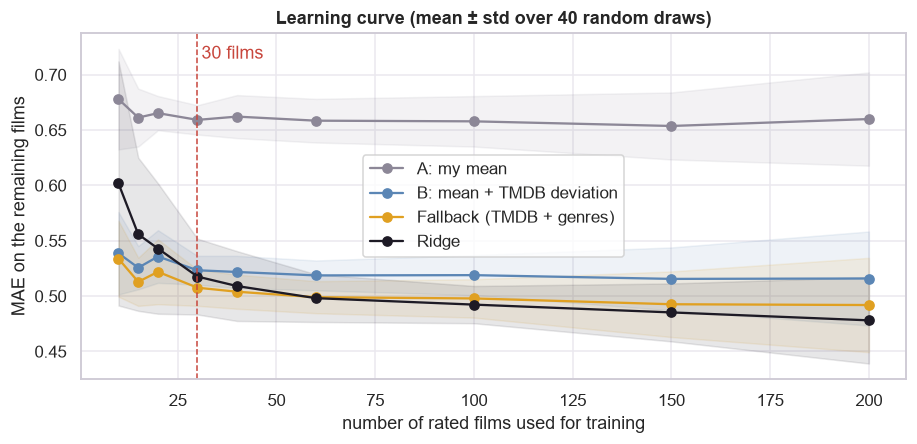

model,A: my mean,B: mean + TMDB deviation,Fallback (TMDB + genres),Ridge
n,,,,
10,0.678,0.539,0.534,0.602
15,0.661,0.526,0.513,0.556
20,0.665,0.536,0.522,0.543
30,0.659,0.523,0.508,0.518
40,0.662,0.522,0.504,0.509
60,0.658,0.519,0.499,0.498
100,0.658,0.519,0.498,0.492
150,0.654,0.516,0.493,0.485
200,0.660,0.516,0.492,0.478


In [22]:
rng = np.random.default_rng(7)
sizes = [10, 15, 20, 30, 40, 60, 100, 150, 200]
lc = []
for n in sizes:
    for _ in range(40):
        idx = rng.permutation(len(df)); tr, te = idx[:n], idx[n:]
        f = FeatureBuilder(); Xtr = f.fit_transform(df.iloc[tr]); Xte = f.transform(df.iloc[te])
        for name_, mk in {"A: my mean": MeanBaseline, "B: mean + TMDB deviation": TmdbDeviationBaseline,
                          "Fallback (TMDB + genres)": Z.TmdbGenreFallback, "Ridge": Z.ridge}.items():
            lc.append({"n": n, "model": name_, "MAE": metrics(y[te], mk().fit(Xtr, y[tr]).predict(Xte))["MAE"]})
lc = pd.DataFrame(lc); lcm = lc.groupby(["n", "model"]).MAE.agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for (name_, d_), c in zip(lcm.groupby("model"), [GREY, "#5b86b5", ACCENT, INK]):
    ax.plot(d_.n, d_["mean"], marker="o", label=name_, color=c); ax.fill_between(d_.n, d_["mean"] - d_["std"], d_["mean"] + d_["std"], color=c, alpha=.1)
ax.axvline(30, color=RED, ls="--", lw=1); ax.text(31, ax.get_ylim()[1] * .985, "30 films", color=RED, va="top")
ax.set(xlabel="number of rated films used for training", ylabel="MAE on the remaining films", title="Learning curve (mean ± std over 40 random draws)"); ax.legend()
plt.tight_layout(); plt.show()
lcm.pivot(index="n", columns="model", values="mean").round(3)

## 8. Conclusions

### 8.1 How much better than the baselines?

| | MAE (stars) | within 0.5★ |
|---|---|---|
| A. always my mean | 0.658 | 49 % |
| B. my mean + TMDB deviation | 0.517 | 58 % |
| Light fallback (TMDB + genres), nested CV | 0.492 | 62 % |
| **Ridge, nested CV (official)** | **0.483** | 60 % |
| Random Forest (best) | 0.473 | 62 % |

* Every model beats "always my mean" by a wide margin (−19 % to −28 % MAE). Most of that improvement, however, comes from **one feature**: the TMDB average. Baseline B, with no learning at all, already gets ~80 % of the way from A to Ridge, and adjusting the score for the number of votes (section 3.3) was worth about 0.005★ to Ridge over the previous hard 50-vote threshold and 0.012★ over the raw score.
* The genuinely *personal* part (genres, decade, director/cast encoding) adds a **modest** gain on top: Ridge is 6.6 % better than Baseline B (−0.034★) and 1.8 % better than the light fallback (−0.009★). It is real (paired Wilcoxon *p* < 0.001 against the plain-fit Ridge) but small in absolute terms, smaller than the fold-to-fold standard deviation of the MAE (≈ 0.05) and much smaller than the granularity of the scale (0.5★).
* Being right to within half a star happens about six times out of ten. That is the honest headline: a useful *ranking* tool for a watchlist, **not** an oracle.
* Director/actor effects, which feel important, carry little weight *in this dataset*: with 191 directors and 141 of them seen once, there is almost nothing to learn from. They matter for the few directors I have seen repeatedly (Nolan, Villeneuve, Scorsese), which is exactly what the Bayesian smoothing preserves.

### 8.2 Which model goes to the web, and why Ridge

* **Random Forest** is the most accurate (MAE 0.473) but its advantage over Ridge's plain fit (0.479) is only 0.005★ and **not statistically significant** (54 % of folds, *p* = 0.16). Against the official nested Ridge number it is 0.010★ better, which is about what the selection optimism of the setup accounts for.
* **Gradient Boosting** is *worse* than Ridge here (0.493 vs 0.479, *p* = 0.002): with ~260 noisy labels it has no room to exploit its flexibility. **k-NN** is clearly worse (0.534): with 25 features and 263 films "similar films" is not well defined.
* A difference of 0.005–0.01 stars is invisible to a user, so we choose by the other criteria the product needs:
  * **Interpretability.** Ridge is additive, so each prediction decomposes exactly into "+0.6 because it is by Christopher Nolan, −0.3 because it is a comedy…". This is a core feature of the app; for a Random Forest we would need an approximation (SHAP).
  * **Trainable in the browser.** Ridge is a closed-form solution of a 25 × 25 linear system: milliseconds in TypeScript, so the app can also run a repeated cross-validation on the user's own ratings to show a *personal* confidence indicator. A 300-tree forest is far heavier to train and to cross-validate repeatedly in JavaScript.
  * **Stability with small data.** Ridge degrades gracefully when the user has fewer films.
* **Light fallback.** The learning curve in 7.4 shows that with fewer than ~60 ratings the director/cast/genre information is too sparse to beat a much simpler rule (at 30 films the fallback has MAE 0.508 vs 0.518 for Ridge), that with 10–20 ratings Ridge is *clearly worse* than Baseline B, and that Ridge only pulls ahead from ~60 films on (0.478 vs 0.492 at 200). The web therefore ships both models: the **TMDB + genres fallback** and Ridge.
* **Which one is used is decided per user, in the browser.** With fewer than 30 ratings the app always uses the fallback. With 30 or more it cross-validates both models on the user's own ratings and uses the personal one whenever its error is lower than or equal to the fallback's (otherwise the fallback). It always shows which model is active and its measured error in plain language.
* **TMDB prior in the web.** The app cannot tune the vote prior per user, so it uses the fixed **m = 500** (centre of the plateau in 3.3) and Ridge with TMDB slope scale 10, and re-fits α on every user's data.

### 8.3 Limitations

* **One user, 263 films.** All conclusions are about *this* person. The *method* is general (and the app re-trains on each visitor's ratings), but I can't claim that Ridge would also be the best model for someone else's taste.
* **Selection bias.** People rate films they chose to watch, which is already filtered by expected enjoyment; the distribution is skewed to high ratings, and we can never learn about films I would have hated but avoided. The model predicts *"given that I watched it"*, not *"would I like a random film"*.
* **The TMDB score is partly the target in disguise.** It aggregates other people's opinions, so a film's TMDB average is not available for upcoming/unreleased titles and changes over time (some of my films are from 2026 and their scores are still moving). Even adjusted, a score with very few votes carries little information, and the app flags such films ("few TMDB ratings: less reliable prediction").
* **Not a confidence interval.** Repeated CV reuses the same films, so the ± are fold-to-fold variability. Hyper-parameters of the Random Forest and Gradient Boosting were fixed a priori (not tuned); Ridge's were chosen by nested CV (6.1), whose result is slightly worse than the plain fit (0.483 vs 0.479): that gap is the optimism that selecting a setup on the same folds introduces. The fixed m = 500 and slope scale used in the web were picked looking at the full CV, so the web model's own number should be read as ≈ 0.48, not 0.477.
* **Ratings are noisy.** A person might give the same film 3.5★ or 4★ on different days; part of the "error" is label noise that no model can remove.
* **Ideas for the future:** text features (plot keywords/overview embeddings), TMDB keywords, collaborative filtering with *other* users' ratings (impossible without a server and a database, which Reelmate deliberately avoids), and ordinal/classification losses that handle the half-star scale.